### Measures of Position (Relative Standing)

- While **central tendency** tells us where the middle of the data is, and **dispersion** tells us how spread out the data is, **measures of position** tell us:
  > **"Where does a specific value stand relative to the rest of the dataset?"**

- Below are simple, practical examples of all primary measures of position with mathematical formulas, plain Python, NumPy, and SciPy implementations:
  1. **Quartiles ($Q_1, Q_2, Q_3$) & Five-Number Summary**
  2. **Percentiles ($P_k$)**
  3. **Deciles ($D_1 \dots D_9$)**
  4. **Percentile Rank**
  5. **Standard Score ($Z$-Score)**
  6. **Modified $Z$-Score (Robust Outlier Detection)**
---
---


### Setup


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statistics

# Set plot style
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Quartiles ($Q_1, Q_2, Q_3$) & Five-Number Summary

* **What it does:** Divides sorted data into **4 equal quarters** (25% each).
* **Key Values:**
  * **$Q_1$ (First / Lower Quartile):** 25th percentile (splits bottom 25% from top 75%).
  * **$Q_2$ (Second Quartile / Median):** 50th percentile (exact middle of the data).
  * **$Q_3$ (Third / Upper Quartile):** 75th percentile (splits bottom 75% from top 25%).
  * **$\text{IQR}$ (Interquartile Range):** $Q_3 - Q_1$ (spread of the middle 50%).
* **Five-Number Summary:** $\text{Min}, \; Q_1, \; Q_2 (\text{Median}), \; Q_3, \; \text{Max}$
* **Naive Example:** 9 student quiz scores: `[12, 15, 18, 20, 22, 25, 28, 30, 35]`


Data: [12, 15, 18, 20, 22, 25, 28, 30, 35]
Minimum       : 12
Q1 (25%)      : 18.0
Q2 (Median)   : 22.0
Q3 (75%)      : 28.0
Maximum       : 35
IQR (Q3 - Q1) : 10.0


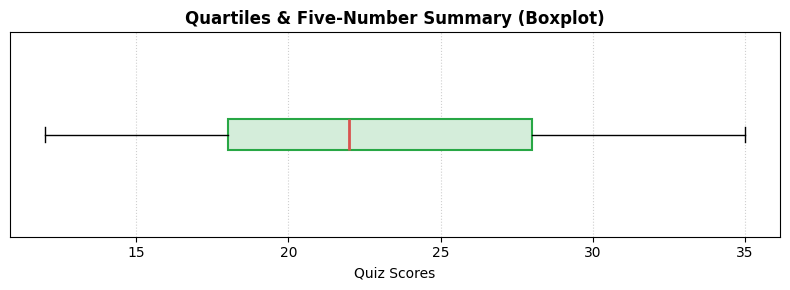

In [ ]:
# 1. Quartiles & Five-Number Summary
scores = [12, 15, 18, 20, 22, 25, 28, 30, 35]

# Using NumPy
q1 = np.percentile(scores, 25)
q2 = np.percentile(scores, 50)  # Median
q3 = np.percentile(scores, 75)
iqr = q3 - q1

min_val = min(scores)
max_val = max(scores)


print(f"Data: {scores}")
print(f"Minimum       : {min_val}")
print(f"Q1 (25%)      : {q1}")
print(f"Q2 (Median)   : {q2}")
print(f"Q3 (75%)      : {q3}")
print(f"Maximum       : {max_val}")
print(f"IQR (Q3 - Q1) : {iqr}")

# Visualizing with a simple Boxplot
plt.figure(figsize=(8, 3))
plt.boxplot(scores, vert=False, patch_artist=True,
            boxprops=dict(facecolor='#d4edda', color='#28a745', lw=1.5),
            medianprops=dict(color='#d9534f', lw=2))

plt.title('Quartiles & Five-Number Summary (Boxplot)', fontweight='bold')
plt.xlabel('Quiz Scores')
plt.yticks([])
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 2. Percentiles ($P_k$)

* **What it does:** Slices sorted data into **100 equal parts**. The $k$-th percentile ($P_k$) is the value below which $k\%$ of the observations fall.
* **Naive Example:**
  * If your score on an exam is at the **90th percentile** ($P_{90}$), it means **90% of students scored below you**, and only 10% scored above you.
  * *(Note: Percentile is NOT percentage marks. You could get 45/100 marks and still be in the 99th percentile if the exam was very hard!)*
* **Common Percentiles:**
  * $P_{25} = Q_1$
  * $P_{50} = \text{Median}$
  * $P_{75} = Q_3$
  * $P_{90} = 90\text{th percentile}$ (commonly used in performance cutoffs)


Marks Dataset: [45, 52, 58, 63, 67, 72, 75, 78, 82, 85, 88, 92, 95]
25th Percentile (P25) : 63.0
50th Percentile (P50) : 75.0 (Median)
75th Percentile (P75) : 85.0
90th Percentile (P90) : 91.2  <-- Top 10% cutoff


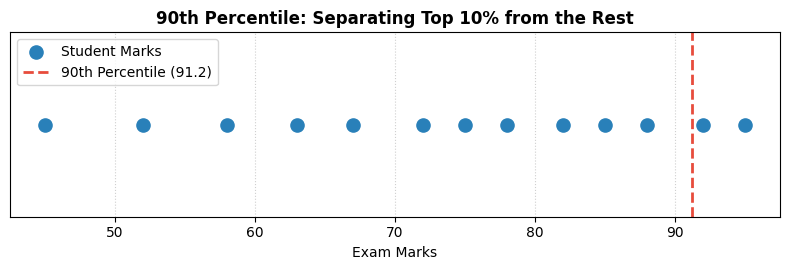

In [6]:
# 2. Percentiles Example
marks = [45, 52, 58, 63, 67, 72, 75, 78, 82, 85, 88, 92, 95]

# Using NumPy
p25 = np.percentile(marks, 25)
p50 = np.percentile(marks, 50)
p75 = np.percentile(marks, 75)
p90 = np.percentile(marks, 90)

print(f"Marks Dataset: {marks}")
print(f"25th Percentile (P25) : {p25:.1f}")
print(f"50th Percentile (P50) : {p50:.1f} (Median)")
print(f"75th Percentile (P75) : {p75:.1f}")
print(f"90th Percentile (P90) : {p90:.1f}  <-- Top 10% cutoff")

# Simple plot showing the 90th percentile threshold
plt.figure(figsize=(8, 2.8))
plt.scatter(marks, [1]*len(marks), color='#2980b9', s=90, label='Student Marks', zorder=3)
plt.axvline(p90, color='#e74c3c', linestyle='--', lw=2, label=f'90th Percentile ({p90:.1f})')
plt.title('90th Percentile: Separating Top 10% from the Rest', fontweight='bold')
plt.xlabel('Exam Marks')
plt.yticks([])
plt.legend()
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 3. Deciles ($D_1$ to $D_9$)

* **What it does:** Divides sorted data into **10 equal groups** (10% each).
* **Notation:**
  * $D_1 = P_{10}$ (cuts bottom 10%)
  * $D_2 = P_{20}$
  * $D_5 = P_{50}$ (Median)
  * $D_9 = P_{90}$ (cuts top 10%)
* **Everyday Application:** Banks and credit card companies divide customer credit risk into **10 deciles** ($D_1$ = lowest risk, $D_{10}$ = highest risk).


Deciles for Monthly Savings:
  D1 (P10) : ₹ 1550.0
  D2 (P20) : ₹ 2100.0
  D3 (P30) : ₹ 2650.0
  D4 (P40) : ₹ 3200.0
  D5 (P50) : ₹ 3850.0
  D6 (P60) : ₹ 4680.0
  D7 (P70) : ₹ 5700.0
  D8 (P80) : ₹ 7200.0
  D9 (P90) : ₹ 8850.0


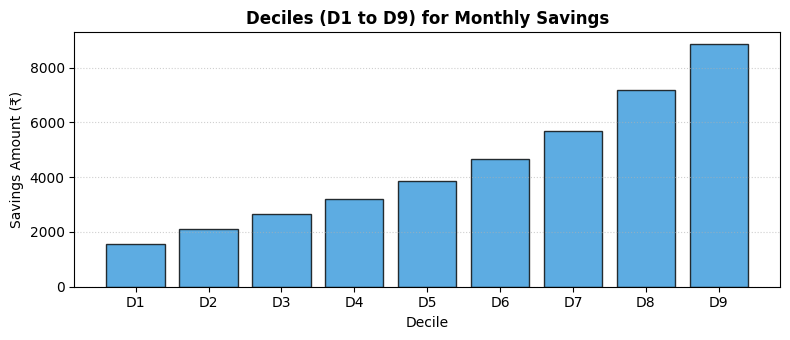

In [8]:
# 3. Deciles (10% slices)
monthly_savings = [1000, 1500, 2000, 2500, 3000, 3500, 4200, 5000, 6000, 7500, 9000, 12000]

# Calculate all 9 deciles (D1 to D9)
deciles = [np.percentile(monthly_savings, d * 10) for d in range(1, 10)]

print("Deciles for Monthly Savings:")
for i, d in enumerate(deciles, 1):
    print(f"  D{i} (P{i*10:2d}) : ₹{d:7.1f}")

# Simple visual plot of Deciles
plt.figure(figsize=(8, 3.5))
plt.bar([f'D{i}' for i in range(1, 10)], deciles, color='#3498db', edgecolor='black', alpha=0.8)
plt.title('Deciles (D1 to D9) for Monthly Savings', fontweight='bold')
plt.xlabel('Decile')
plt.ylabel('Savings Amount (₹)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 4. Percentile Rank

* **What it does:** The exact reverse of percentile.
  * **Percentile:** You give a percentage (e.g. 75%), it returns a value (e.g. 78 marks).
  * **Percentile Rank:** You give a specific value (e.g. 78 marks), it returns what percentage of students scored below you.
* **Mathematical Formula:**
  $$\text{Percentile Rank}(x) = \frac{\text{Number of values } < x}{\text{Total Number of values}} \times 100$$
* **Naive Example:** In a class of 10 students, if 7 students scored less than you, your percentile rank is $7/10 \times 100 = 70\%$.
* **Python tool:** `scipy.stats.percentileofscore(data, score)`


Class Scores   : [40, 50, 55, 60, 65, 70, 75, 80, 85, 90]
My Score       : 75
Scores below me: 6 out of 10
Percentile Rank (Plain Python): 60.0%
Percentile Rank (SciPy)       : 60.0%
Meaning: You scored higher than 60% of the class!


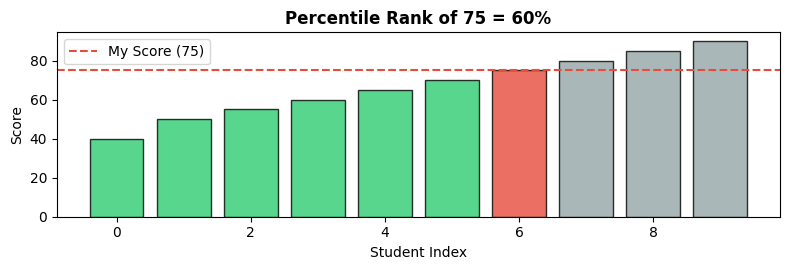

In [10]:
# 4. Percentile Rank Example
class_scores = [40, 50, 55, 60, 65, 70, 75, 80, 85, 90]
my_score = 75

# Plain Python
count_below = sum(1 for s in class_scores if s < my_score)
pr_python = (count_below / len(class_scores)) * 100

# Using SciPy
pr_scipy = stats.percentileofscore(class_scores, my_score, kind='strict')

print(f"Class Scores   : {class_scores}")
print(f"My Score       : {my_score}")
print(f"Scores below me: {count_below} out of {len(class_scores)}")
print(f"Percentile Rank (Plain Python): {pr_python:.1f}%")
print(f"Percentile Rank (SciPy)       : {pr_scipy:.1f}%")
print(f"Meaning: You scored higher than {pr_python:.0f}% of the class!")

# Visual display
plt.figure(figsize=(8, 2.8))
colors = ['#2ecc71' if s < my_score else ('#e74c3c' if s == my_score else '#95a5a6') for s in class_scores]
plt.bar(range(len(class_scores)), class_scores, color=colors, edgecolor='black', alpha=0.8)
plt.axhline(my_score, color='#e74c3c', linestyle='--', label=f'My Score ({my_score})')
plt.title(f'Percentile Rank of {my_score} = {pr_python:.0f}%', fontweight='bold')
plt.xlabel('Student Index')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()


---
## 5. Standard Score ($Z$-Score)

* **What it does:** Measures **how many standard deviations** an observation is away from the mean.
* **Mathematical Formula:**
  $$z = \frac{x - \bar{x}}{s} \quad \text{(Sample)} \qquad Z = \frac{x - \mu}{\sigma} \quad \text{(Population)}$$
  *Where:*
  * $x$: The value you want to check
  * $\bar{x}$: Mean (average) of the dataset
  * $s$: Standard deviation
* **How to Interpret $Z$:**
  * $z = 0$: Exactly at the average.
  * $z = +1.0$: Exactly 1 standard deviation **above** the average.
  * $z = -2.0$: Exactly 2 standard deviations **below** the average.
  * $|z| > 3.0$: Considered a **rare outlier** in a normal distribution!


Heights: [160, 165, 170, 172, 175, 178, 182, 195]
Mean   : 174.6 cm
Std Dev: 10.8 cm
----------------------------------------
Height     | Z-Score    | Interpretation
----------------------------------------
160        | -1.35     | Below average
165        | -0.89     | Typical height
170        | -0.43     | Typical height
172        | -0.24     | Typical height
175        | +0.03     | Typical height
178        | +0.31     | Typical height
182        | +0.68     | Typical height
195        | +1.89     | Typical height


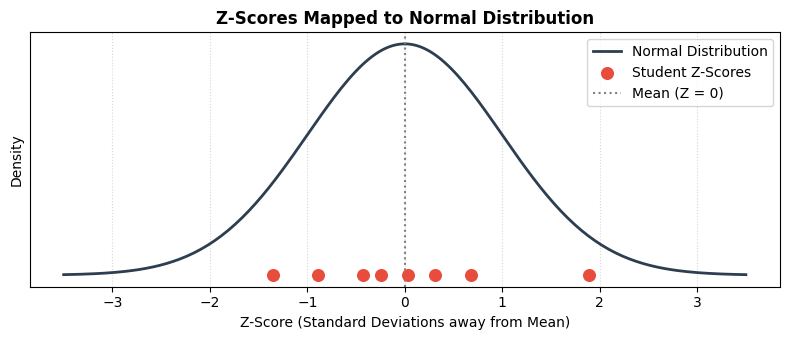

In [12]:
# 5. Z-Score Example
heights = [160, 165, 170, 172, 175, 178, 182, 195]

mean_h = np.mean(heights)
std_h = np.std(heights, ddof=1) # sample std

# Plain Python
z_python = [(x - mean_h) / std_h for x in heights]

# SciPy
z_scipy = stats.zscore(heights, ddof=1)

print(f"Heights: {heights}")
print(f"Mean   : {mean_h:.1f} cm")
print(f"Std Dev: {std_h:.1f} cm")
print("-" * 40)
print(f"{'Height':<10} | {'Z-Score':<10} | {'Interpretation'}")
print("-" * 40)
for h, z in zip(heights, z_scipy):
    if z > 2.0:
        desc = "Much taller than average"
    elif z < -1.0:
        desc = "Below average"
    else:
        desc = "Typical height"
    print(f"{h:<10} | {z:+.2f}     | {desc}")

# Visualizing Z-scores with standard normal curve
x_curve = np.linspace(-3.5, 3.5, 200)
y_curve = stats.norm.pdf(x_curve, 0, 1)

plt.figure(figsize=(8, 3.5))
plt.plot(x_curve, y_curve, color='#2c3e50', lw=2, label='Normal Distribution')
plt.scatter(z_scipy, np.zeros_like(z_scipy), color='#e74c3c', s=70, zorder=4, label='Student Z-Scores')
plt.axvline(0, color='gray', linestyle=':', label='Mean (Z = 0)')
plt.title('Z-Scores Mapped to Normal Distribution', fontweight='bold')
plt.xlabel('Z-Score (Standard Deviations away from Mean)')
plt.ylabel('Density')
plt.yticks([])
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 6. Modified $Z$-Score (Robust Against Outliers)

* **Why do we need it?**
  * Standard $Z$-score uses **Mean** and **Standard Deviation**.
  * When an extreme outlier is present (e.g., a typing error of 500), it drags the mean way up and inflates the standard deviation!
  * This "hides" other outliers (known as the **masking effect**).
* **The Solution: Modified $Z$-Score ($M_i$):**
  Uses the **Median** and **Median Absolute Deviation (MAD)** instead of mean and standard deviation:
  $$M_i = \frac{0.6745 \cdot (x_i - \text{Median})}{\text{MAD}}$$
  *Where $\text{MAD} = \text{median}(|x_i - \text{Median}|)$*
* **Rule of Thumb:** If $|M_i| > 3.5$, it is an **outlier**.


Data: [20, 21, 22, 21, 23, 20, 22, 21, 250]
Mean = 46.7°C (Distorted by 250!) | Median = 21.0°C (Completely robust)
-------------------------------------------------------
Value    | Standard Z   | Modified Z   | Modified Flag
-------------------------------------------------------
20       |    -0.35     |    -0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
22       |    -0.32     |    +0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
23       |    -0.31     |    +1.35     | Normal
20       |    -0.35     |    -0.67     | Normal
22       |    -0.32     |    +0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
250      |    +2.67     |  +154.46     | OUTLIER! (|M| > 3.5)


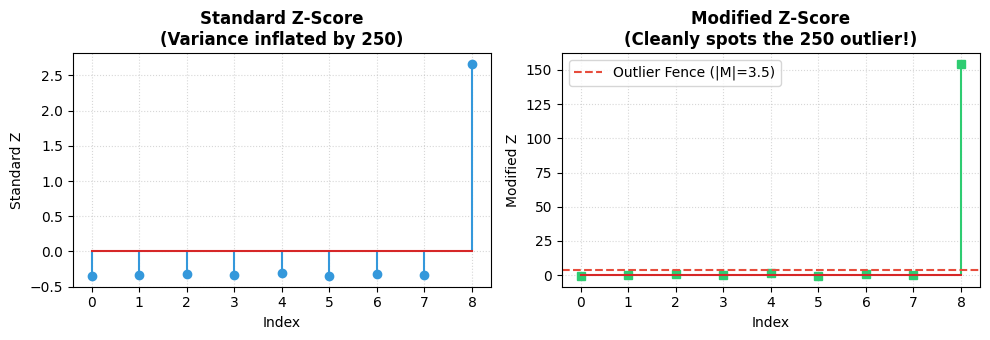

In [14]:
# 6. Modified Z-Score vs. Standard Z-Score with an Outlier
# Notice the massive typing mistake at the end (250°C instead of ~22°C)
temps = [20, 21, 22, 21, 23, 20, 22, 21, 250]

# Standard Z-Score
mean_t = np.mean(temps)
std_t = np.std(temps, ddof=1)
z_standard = [(x - mean_t) / std_t for x in temps]

# Modified Z-Score
med_t = np.median(temps)
mad_t = stats.median_abs_deviation(temps)
z_modified = [0.6745 * (x - med_t) / mad_t for x in temps]

print(f"Data: {temps}")
print(f"Mean = {mean_t:.1f}°C (Distorted by 250!) | Median = {med_t:.1f}°C (Completely robust)")
print("-" * 55)
print(f"{'Value':<8} | {'Standard Z':<12} | {'Modified Z':<12} | {'Modified Flag'}")
print("-" * 55)
for x, sz, mz in zip(temps, z_standard, z_modified):
    flag = "OUTLIER! (|M| > 3.5)" if abs(mz) > 3.5 else "Normal"
    print(f"{x:<8} | {sz:+8.2f}     | {mz:+8.2f}     | {flag}")

# Comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)

ax1.stem(range(len(temps)), z_standard, linefmt='#3498db', markerfmt='o')
ax1.set_title('Standard Z-Score\n(Variance inflated by 250)', fontweight='bold')
ax1.set_xlabel('Index')
ax1.set_ylabel('Standard Z')
ax1.grid(True, linestyle=':', alpha=0.5)

ax2.stem(range(len(temps)), z_modified, linefmt='#2ecc71', markerfmt='s')
ax2.axhline(3.5, color='#e74c3c', linestyle='--', label='Outlier Fence (|M|=3.5)')
ax2.set_title('Modified Z-Score\n(Cleanly spots the 250 outlier!)', fontweight='bold')
ax2.set_xlabel('Index')
ax2.set_ylabel('Modified Z')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Quick Summary & Cheat Sheet

| Measure | What it answers | Formula / Function | When to use |
| :--- | :--- | :--- | :--- |
| **Quartiles ($Q_1, Q_2, Q_3$)** | Splits data into 4 quarters | `np.percentile(data, [25, 50, 75])` | Boxplots, Five-Number Summary, IQR |
| **Percentile ($P_k$)** | What value separates the bottom $k\%$? | `np.percentile(data, k)` | Competitive exams (CAT, GATE), SLA metrics |
| **Deciles ($D_1 \dots D_9$)** | Splits data into 10 groups | `np.percentile(data, [10, 20, ..., 90])` | Credit risk scoring, customer tiering |
| **Percentile Rank** | What percentage of data is below $x$? | `stats.percentileofscore(data, x)` | Reporting personal standing vs. peers |
| **$Z$-Score** | How many std deviations away from mean? | $z = \frac{x - \bar{x}}{s}$ or `stats.zscore(data)` | Normal / bell-shaped data, standardized comparisons |
| **Modified $Z$-Score** | Is this value an outlier without being masked? | $M_i = \frac{0.6745(x_i - \text{Median})}{\text{MAD}}$ | Skewed data or data with extreme outliers |
